# Tự Động Huấn Luyện & So Sánh Nhiều Cấu Hình (Chạy Được Cả Local & Kaggle)
Notebook này được tối ưu sẵn để **chạy trực tiếp trên Kaggle GPU (T4 / P100)** hoặc trên máy cá nhân:
1. **Tự động nhận diện môi trường:** Tự động tìm đường dẫn dataset GoPro.
2. **Tích hợp Dataset:** Khắc phục lỗi thiếu file `utils.dataset` bằng cách khai báo trực tiếp class `GoProDeblurDataset`.
3. **Danh sách cấu hình (`CONFIG_LIST`):** Tự động huấn luyện lần lượt từng cấu hình.
4. **Lưu trữ riêng biệt:** Mỗi cấu hình có file checkpoint `.pth` riêng.
5. **Bảng xếp hạng:** Tự động xuất bảng so sánh PSNR, SSIM, Loss.
6. **Fine-Tuning & Visual Demo:** Tinh chỉnh mô hình tốt nhất và render ảnh so sánh.

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import math
import sys
import time
import random
import gc
import json
import shutil
import urllib.request
import glob
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# Tạo thư mục weights để lưu checkpoint
os.makedirs("weights", exist_ok=True)

candidate_paths = [
    '.', '..', 
    '/kaggle/working', 
    '/kaggle/working/Image-processing-project-integrating-MoE-and-Q-Former'
]

for p in candidate_paths:
    if os.path.exists(os.path.join(p, 'models')) and os.path.exists(os.path.join(p, 'utils')):
        abs_p = os.path.abspath(p)
        if abs_p not in sys.path:
            sys.path.insert(0, abs_p)
        break

# Import từ thư mục dự án
try:
    from models.forge import NAFNetBaseline, FORGEDeblurNet
    from utils.metrics import CharbonnierLoss, calc_psnr, calc_ssim, count_parameters
    from utils.dataset import MultiTaskRestorationDataset, get_multitask_balanced_splits
except ImportError as e:
    print(f"Cảnh báo Import: {e}. Vui lòng kiểm tra lại cấu trúc thư mục models/ và utils/.")

# ------------------------------------------------------------------------------
# Định nghĩa WarmupCosineScheduler để tránh lỗi NameError / Undefined Variable
# ------------------------------------------------------------------------------
class WarmupCosineScheduler(optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, warmup_epochs, total_epochs, min_lr=1e-7, last_epoch=-1):
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        if self.last_epoch < self.warmup_epochs:
            alpha = float(self.last_epoch + 1) / float(max(1, self.warmup_epochs))
            return [base_lr * alpha for base_lr in self.base_lrs]
        else:
            progress = float(self.last_epoch - self.warmup_epochs) / float(max(1, self.total_epochs - self.warmup_epochs))
            progress = min(1.0, max(0.0, progress))
            cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
            return [self.min_lr + (base_lr - self.min_lr) * cosine_decay for base_lr in self.base_lrs]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Thiết bị đang sử dụng: {device}")

pretrained_url = "https://huggingface.co/Jacid23/third-eye-models/resolve/5c2e322323888d8d26852f06715ccc6eb61ea795/NAFNet-GoPro-width64.pth"
nafnet_ckpt_path = os.path.join("weights", "NAFNet-GoPro-width64.pth")

if not os.path.exists(nafnet_ckpt_path):
    print("--> Đang tải pretrained NAFNet từ Hugging Face...")
    urllib.request.urlretrieve(pretrained_url, nafnet_ckpt_path)
    print("--> Tải xuống checkpoint thành công!")
else:
    print(f"--> Đã tìm thấy checkpoint tại: {nafnet_ckpt_path}")

nafnet_state_dict = torch.load(nafnet_ckpt_path, map_location=device)
if 'params' in nafnet_state_dict:
    nafnet_state_dict = nafnet_state_dict['params']
elif 'model_state_dict' in nafnet_state_dict:
    nafnet_state_dict = nafnet_state_dict['model_state_dict']
print("--> Đã nạp thành công nafnet_state_dict vào bộ nhớ!")

Thiết bị đang sử dụng: cuda
--> Đang tải pretrained NAFNet từ Hugging Face...


ContentTooShortError: <urlopen error retrieval incomplete: got only 47720446 out of 271778961 bytes>

### Khởi tạo Dữ liệu và Hàm Đánh Giá

In [2]:
def auto_detect_multitask_dataset():
    candidate_names = ['dataset_multitask_unified', 'multitask_dataset']
    prefixes = ['.', '..', '/kaggle/input/*', '/kaggle/input']
    
    for prefix in prefixes:
        for path in glob.glob(prefix):
            for c_name in candidate_names:
                full_p = os.path.join(path, c_name)
                if os.path.exists(full_p):
                    return os.path.abspath(full_p)
    return 'dataset_multitask_unified'

multitask_dir = auto_detect_multitask_dataset()
print(f"--> Đã tìm thấy đường dẫn Multitask Dataset: {multitask_dir}")

# Giới hạn số lượng ảnh
MAX_TRAIN_SAMPLES = 1200  # Giới hạn train/task (nguồn từ train/)
MAX_TEST_SAMPLES = 200    # Giới hạn test/task (nguồn chuẩn từ test/)

# Tự động chia dataset cân bằng theo từng task
train_samples, val_samples, test_samples = get_multitask_balanced_splits(
    root_dir=multitask_dir,
    val_ratio=0.15,
    seed=42,
    max_train_samples_per_task=MAX_TRAIN_SAMPLES,
    max_test_samples_per_task=MAX_TEST_SAMPLES
)

# Khởi tạo các tập Dataset
train_sub_ds = MultiTaskRestorationDataset(samples=train_samples, crop_size=192, is_train=True)
val_sub_ds = MultiTaskRestorationDataset(samples=val_samples, crop_size=256, is_train=False)
test_sub_ds = MultiTaskRestorationDataset(samples=test_samples, crop_size=256, is_train=False)

# DataLoader
num_workers_cfg = 0 if os.name == 'nt' else 2
val_loader = DataLoader(val_sub_ds, batch_size=1, shuffle=False, num_workers=num_workers_cfg, pin_memory=True)
test_loader = DataLoader(test_sub_ds, batch_size=1, shuffle=False, num_workers=num_workers_cfg, pin_memory=True)

print(f"--> Khởi tạo thành công DataLoader: Train={len(train_sub_ds)} | Val={len(val_sub_ds)} | Test={len(test_sub_ds)}")

--> Đã tìm thấy đường dẫn Multitask Dataset: e:\DuAn\Image-processing-project-integrating-MoE-and-Q-Former\dataset_multitask_unified
--> [Split Data] Phân chia dữ liệu từ: e:\DuAn\Image-processing-project-integrating-MoE-and-Q-Former\dataset_multitask_unified
     + TRAIN / VAL : Nguồn từ folder <task>/train/ (Giới hạn max 1200 ảnh/task)
     + TEST        : Nguồn từ folder <task>/test/  (Giới hạn max 200 ảnh/task)
  + Task [deblur  ] (ID: 0): Train =  750 | Val = 400 | Test (Gốc) = 100
  + Task [dehaze  ] (ID: 1): Train = 1010 | Val = 175 | Test (Gốc) = 175
  + Task [denoise ] (ID: 2): Train =   98 | Val =  19 | Test (Gốc) =  42
  + Task [derain  ] (ID: 3): Train = 1020 | Val = 180 | Test (Gốc) = 200
  + Task [desnow  ] (ID: 4): Train = 1020 | Val = 180 | Test (Gốc) = 200
  + Task [lowlight] (ID: 5): Train =  589 | Val = 100 | Test (Gốc) = 100
--------------------------------------------------------------------------------
--> TỔNG CỘNG: Train = 4487 | Val = 1054 | Test = 817 ảnh
--> 

In [3]:
import math
import torch
import torch.nn.functional as F
from collections import defaultdict
from tqdm.auto import tqdm

def evaluate_multitask_model(model, loader, desc="Validating", max_size=1024):
    model.eval()
    task_psnr = defaultdict(list)
    task_ssim = defaultdict(list)
    
    multiple = 16 
    pbar_eval = tqdm(loader, desc=f"[{desc}]", leave=False)
    
    with torch.no_grad():
        for inputs, targets, task_ids, task_names in pbar_eval:
            inputs, targets = inputs.to(device), targets.to(device)

            # 1. Center Crop nếu ảnh quá lớn để tránh OOM
            _, _, h_orig, w_orig = inputs.shape
            if h_orig > max_size or w_orig > max_size:
                h_crop = min(h_orig, max_size)
                w_crop = min(w_orig, max_size)
                top = (h_orig - h_crop) // 2
                left = (w_orig - w_crop) // 2
                inputs = inputs[:, :, top:top+h_crop, left:left+w_crop]
                targets = targets[:, :, top:top+h_crop, left:left+w_crop]

            # 2. Padding để H và W chia hết cho 16
            h, w = inputs.shape[2], inputs.shape[3]
            H = ((h + multiple - 1) // multiple) * multiple
            W = ((w + multiple - 1) // multiple) * multiple
            pad_h, pad_w = H - h, W - w
            inputs_padded = F.pad(inputs, (0, pad_w, 0, pad_h), mode='reflect')

            # 3. CHÚ Ý: Đánh giá bằng FP32 (float32) để tránh trào số NaN ở LayerNorm
            out = model(inputs_padded.float())

            preds = out[0] if isinstance(out, tuple) else out
            preds = preds[:, :, :h, :w]
            preds = torch.clamp(preds, 0.0, 1.0)
            
            # 4. Tính toán metric
            p_val = calc_psnr(preds, targets)
            s_val = calc_ssim(preds, targets)
            
            p_item = p_val.item() if torch.is_tensor(p_val) else p_val
            s_item = s_val.item() if torch.is_tensor(s_val) else s_val

            for t_name in task_names:
                if not math.isnan(p_item):
                    task_psnr[t_name].append(p_item)
                if not math.isnan(s_item):
                    task_ssim[t_name].append(s_item)

    # Tính trung bình an toàn (bỏ qua NaN nếu có)
    all_psnr = [val for sublist in task_psnr.values() for val in sublist if not math.isnan(val)]
    all_ssim = [val for sublist in task_ssim.values() for val in sublist if not math.isnan(val)]
    
    avg_psnr = sum(all_psnr) / len(all_psnr) if all_psnr else 0.0
    avg_ssim = sum(all_ssim) / len(all_ssim) if all_ssim else 0.0

    task_summary = {}
    for t_name in task_psnr:
        p_list = [v for v in task_psnr[t_name] if not math.isnan(v)]
        s_list = [v for v in task_ssim[t_name] if not math.isnan(v)]
        t_p = sum(p_list) / len(p_list) if p_list else 0.0
        t_s = sum(s_list) / len(s_list) if s_list else 0.0
        task_summary[t_name] = {'psnr': t_p, 'ssim': t_s}

    return avg_psnr, avg_ssim, task_summary

### Đánh giá baseline NAFNet gốc

In [4]:
baseline_model = NAFNetBaseline(
    img_channel=3, 
    width=64, 
    enc_blk_nums=[1, 1, 1, 28], 
    middle_blk_num=1, 
    dec_blk_nums=[1, 1, 1, 1]
).to(device)

baseline_model.load_state_dict(nafnet_state_dict, strict=True)

print("\n===================================================")
print(" ĐANG ĐÁNH GIÁ PURE NAFNet BASELINE TRÊN TẬP TEST MULTITASK...")
print("===================================================")
baseline_psnr, baseline_ssim, baseline_summary = evaluate_multitask_model(baseline_model, test_loader, desc="Baseline Test")

print(f"\n KẾT QUẢ PURE NAFNET BASELINE (TRUNG BÌNH CÁC TASK):")
print(f"   + PSNR Trung bình : {baseline_psnr:.2f} dB")
print(f"   + SSIM Trung bình : {baseline_ssim:.4f}")
print("\n CHI TIẾT THEO TỪNG TASK:")
for t_name, metrics in sorted(baseline_summary.items()):
    print(f"   - Task [{t_name:8s}]: PSNR = {metrics['psnr']:.2f} dB | SSIM = {metrics['ssim']:.4f}")

del baseline_model
gc.collect()
torch.cuda.empty_cache()


 ĐANG ĐÁNH GIÁ PURE NAFNet BASELINE TRÊN TẬP TEST MULTITASK...


[Baseline Test]:   0%|          | 0/817 [00:00<?, ?it/s]


 KẾT QUẢ PURE NAFNET BASELINE (TRUNG BÌNH CÁC TASK):
   + PSNR Trung bình : 19.43 dB
   + SSIM Trung bình : 0.6408

 CHI TIẾT THEO TỪNG TASK:
   - Task [deblur  ]: PSNR = 32.38 dB | SSIM = 0.9285
   - Task [dehaze  ]: PSNR = 16.29 dB | SSIM = 0.7746
   - Task [denoise ]: PSNR = 14.67 dB | SSIM = 0.2781
   - Task [derain  ]: PSNR = 20.88 dB | SSIM = 0.6416
   - Task [desnow  ]: PSNR = 20.26 dB | SSIM = 0.6858
   - Task [lowlight]: PSNR = 9.45 dB | SSIM = 0.1794


### Huấn Luyện Tinh Chỉnh (Fine-Tuning) & Đánh Giá Sau Cùng

In [6]:
# ==============================================================================
# MAIN TRAIN - CHẠY FP32 THUẦN (CHỐNG NaN TUYỆT ĐỐI CHO NAFNET + MoE)
# ==============================================================================
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
import os
import gc

BEST_CONFIG = {
    'name': 'FORGE_MoE_MainTrain',
    'lr': 1e-4,
    'batch_size': 2,
    'freeze_backbone': True,
}

COMMON_CONFIG = {
    'width': 64,
    'enc_blk_nums': [1, 1, 1, 28],
    'middle_blk_num': 1,
    'dec_blk_nums': [1, 1, 1, 1],
    'num_queries': 16,
    'num_experts': 4,
    'r': 16,
    'rb': 32,
    'aux_weight': 1e-4,
    'moe_in_decoder': False,
}

MAX_FINE_TUNE_EPOCHS = 15  
PATIENCE = 5               
MIN_DELTA = 0.02           

print(f"\n===================================================")
print(f" BẮT ĐẦU HUẤN LUYỆN KỸ MÔ HÌNH FORGE MoE (FP32 - Safe Mode)")
print(f"===================================================")

num_workers_ft = 0 if os.name == 'nt' else 2
train_loader_full = DataLoader(
    train_sub_ds, 
    batch_size=BEST_CONFIG['batch_size'], 
    shuffle=True, 
    num_workers=num_workers_ft, 
    pin_memory=True
)

final_model = FORGEDeblurNet(
    img_channel=3, 
    out_channels=3,
    width=COMMON_CONFIG['width'],
    enc_blk_nums=COMMON_CONFIG['enc_blk_nums'],
    middle_blk_num=COMMON_CONFIG['middle_blk_num'],
    dec_blk_nums=COMMON_CONFIG['dec_blk_nums'],
    num_queries=COMMON_CONFIG['num_queries'], 
    num_experts=COMMON_CONFIG['num_experts'],
    r=COMMON_CONFIG['r'],
    rb=COMMON_CONFIG['rb'],
    moe_in_decoder=COMMON_CONFIG['moe_in_decoder'],
).to(device)

# Nạp pretrained weight
final_model.load_state_dict(nafnet_state_dict, strict=False)

if BEST_CONFIG['freeze_backbone']:
    final_model.freeze_backbone(True)

trainable_params = [p for p in final_model.parameters() if p.requires_grad]
n_trainable = sum(p.numel() for p in trainable_params)
n_total = sum(p.numel() for p in final_model.parameters())
print(f"--> Số tham số huấn luyện: {n_trainable:,} / {n_total:,} ({100*n_trainable/n_total:.1f}%)")

optimizer = optim.AdamW(trainable_params, lr=BEST_CONFIG['lr'], weight_decay=1e-4)
scheduler = WarmupCosineScheduler(optimizer, warmup_epochs=1, total_epochs=MAX_FINE_TUNE_EPOCHS, min_lr=1e-7)
criterion = CharbonnierLoss()

best_val_psnr = 0.0
no_improve_epochs = 0
best_checkpoint_path = os.path.join("weights", f"best_model_{BEST_CONFIG['name']}.pth")

for epoch in range(1, MAX_FINE_TUNE_EPOCHS + 1):
    final_model.train()
    running_loss = 0.0
    valid_batches = 0
    
    pbar = tqdm(train_loader_full, desc=f"[Main Train] Epoch {epoch:02d}/{MAX_FINE_TUNE_EPOCHS:02d}")
    
    for inputs, targets, task_ids, task_names in pbar:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad(set_to_none=True)
        
        # 1. Tính toán chuẩn FP32 float32
        preds, aux_loss = final_model(inputs.float())
        recon_loss = criterion(preds, targets.float())
        
        # Đảm bảo aux_loss không bị NaN
        if torch.isnan(aux_loss) or torch.isinf(aux_loss):
            aux_loss = torch.tensor(0.0, device=device)
            
        total_loss = recon_loss + COMMON_CONFIG['aux_weight'] * aux_loss
        
        # 2. Kiểm tra nếu loss bị NaN thì bỏ qua batch lỗi này
        if torch.isnan(total_loss) or torch.isinf(total_loss):
            print(f"\n Cảnh báo: Phát hiện NaN loss ở batch, bỏ qua update batch này.")
            continue
            
        total_loss.backward()
        
        # 3. Clip gradient để chống nổ gradient
        torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
        optimizer.step()
            
        running_loss += total_loss.item()
        valid_batches += 1
        pbar.set_postfix({'loss': f"{total_loss.item():.4f}", 'lr': f"{optimizer.param_groups[0]['lr']:.2e}"})
        
        del inputs, targets, preds
        
    epoch_loss = running_loss / max(1, valid_batches)
    scheduler.step()
    
    # Validation Check
    val_psnr, val_ssim, val_summary = evaluate_multitask_model(final_model, val_loader, desc="Validation Check")
    print(f"--> [Epoch {epoch:02d}] Train Loss: {epoch_loss:.4f} | Val PSNR: {val_psnr:.2f} dB | SSIM: {val_ssim:.4f}")
    
    if val_psnr - best_val_psnr > MIN_DELTA:
        best_val_psnr = val_psnr
        no_improve_epochs = 0
        torch.save(final_model.state_dict(), best_checkpoint_path)
        print(f"    [+] Cải thiện PSNR. Đã lưu checkpoint: {best_checkpoint_path}")
    else:
        no_improve_epochs += 1
        print(f"    [-] Không cải thiện ({no_improve_epochs}/{PATIENCE} epoch).")
        
    if no_improve_epochs >= PATIENCE:
        print(f"\n KÍCH HOẠT EARLY STOPPING.")
        break

gc.collect()
torch.cuda.empty_cache()


 BẮT ĐẦU HUẤN LUYỆN KỸ MÔ HÌNH FORGE MoE (FP32 - Safe Mode)
--> Số tham số huấn luyện: 579,993 / 68,433,241 (0.8%)


[Main Train] Epoch 01/15:   0%|          | 0/2244 [00:00<?, ?it/s]

[Validation Check]:   0%|          | 0/1054 [00:00<?, ?it/s]

--> [Epoch 01] Train Loss: 25.4073 | Val PSNR: 23.77 dB | SSIM: 0.7427
    [+] Cải thiện PSNR. Đã lưu checkpoint: weights\best_model_FORGE_MoE_MainTrain.pth


[Main Train] Epoch 02/15:   0%|          | 0/2244 [00:00<?, ?it/s]

...

[Validation Check]:   0%|          | 0/1054 [00:00<?, ?it/s]

--> [Epoch 14] Train Loss: 4.5874 | Val PSNR: 25.54 dB | SSIM: 0.7651
    [-] Không cải thiện (2/5 epoch).


[Main Train] Epoch 15/15:   0%|          | 0/2244 [00:00<?, ?it/s]

[Validation Check]:   0%|          | 0/1054 [00:00<?, ?it/s]

--> [Epoch 15] Train Loss: 4.1875 | Val PSNR: 25.56 dB | SSIM: 0.7656
    [-] Không cải thiện (3/5 epoch).


### Trực Quan Hóa Kết Quả (Visual Demo)

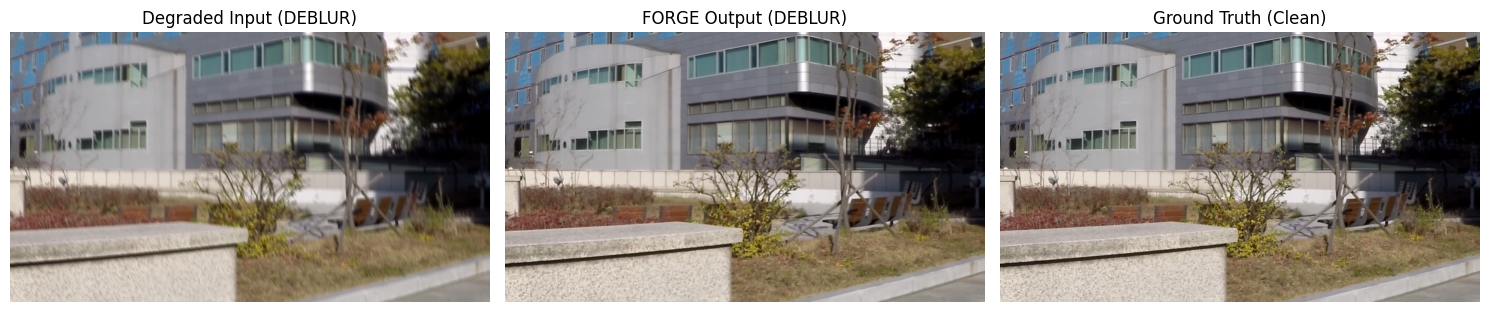

In [7]:
def visualize_results(model, loader, num_imgs=3):
    model.eval()
    inputs, targets, task_ids, task_names = next(iter(loader))
    inputs, targets = inputs.to(device), targets.to(device)
    
    with torch.no_grad():
        out = model(inputs)
        preds = out[0] if isinstance(out, tuple) else out
        preds = torch.clamp(preds, 0.0, 1.0)
    
    inputs = inputs.cpu()
    targets = targets.cpu()
    preds = preds.cpu()
    
    batch_size = min(num_imgs, inputs.size(0))
    fig, axes = plt.subplots(batch_size, 3, figsize=(15, 5 * batch_size))
    
    if batch_size == 1:
        axes = [axes]
        
    for i in range(batch_size):
        t_name = task_names[i] if isinstance(task_names, (list, tuple)) else task_names
        axes[i][0].imshow(inputs[i].permute(1, 2, 0))
        axes[i][0].set_title(f"Degraded Input ({t_name.upper()})")
        axes[i][0].axis('off')
        
        axes[i][1].imshow(preds[i].permute(1, 2, 0))
        axes[i][1].set_title(f"FORGE Output ({t_name.upper()})")
        axes[i][1].axis('off')
        
        axes[i][2].imshow(targets[i].permute(1, 2, 0))
        axes[i][2].set_title("Ground Truth (Clean)")
        axes[i][2].axis('off')
        
    plt.tight_layout()
    plt.show()

visualize_results(final_model, test_loader, num_imgs=3)

In [8]:
best_model = FORGEDeblurNet(
    img_channel=3,
    out_channels=3,
    width=COMMON_CONFIG['width'],
    enc_blk_nums=COMMON_CONFIG['enc_blk_nums'],
    middle_blk_num=COMMON_CONFIG['middle_blk_num'],
    dec_blk_nums=COMMON_CONFIG['dec_blk_nums'],
    num_queries=COMMON_CONFIG['num_queries'],
    num_experts=COMMON_CONFIG['num_experts'],
    r=COMMON_CONFIG['r'],
    rb=COMMON_CONFIG['rb'],
    moe_in_decoder=COMMON_CONFIG.get('moe_in_decoder', False),
    decoder_r=COMMON_CONFIG.get('decoder_r', None),
    decoder_rb=COMMON_CONFIG.get('decoder_rb', None),
).to(device)

best_checkpoint_path = os.path.join("weights", f"best_model_{BEST_CONFIG['name']}.pth")

if os.path.exists(best_checkpoint_path):
    best_state_dict = torch.load(best_checkpoint_path, map_location=device)
    best_model.load_state_dict(best_state_dict, strict=True)
    print(f"--> Đã nạp checkpoint thành công từ: {best_checkpoint_path}")
else:
    print(f"--> Cảnh báo: Không tìm thấy checkpoint {best_checkpoint_path}, đánh giá bằng trọng số hiện tại của mô hình.")

print("\n===================================================")
print(f" ĐANG ĐÁNH GIÁ MÔ HÌNH BEST FORGE ({BEST_CONFIG['name']}) TRÊN TẬP TEST...")
print("===================================================")

forge_psnr, forge_ssim, forge_summary = evaluate_multitask_model(best_model, test_loader, desc="FORGE Best Test")

print(f"\n KẾT QUẢ TỔNG QUAN MÔ HÌNH FORGE ({BEST_CONFIG['name']}):")
print(f"   + PSNR Trung bình : {forge_psnr:.2f} dB")
print(f"   + SSIM Trung bình : {forge_ssim:.4f}")

if 'baseline_psnr' in locals():
    print(f"   + Cải thiện so với Baseline : {forge_psnr - baseline_psnr:+.2f} dB PSNR | {forge_ssim - baseline_ssim:+.4f} SSIM")

print("\n BẢNG KẾT QUẢ CHI TIẾT CÁC TÁC VỤ:")
for t_name, metrics in sorted(forge_summary.items()):
    base_p = baseline_summary[t_name]['psnr'] if 'baseline_summary' in locals() and t_name in baseline_summary else None
    diff_str = f" (Δ vs Base: {metrics['psnr'] - base_p:+.2f} dB)" if base_p is not None else ""
    print(f"   - Task [{t_name:8s}]: PSNR = {metrics['psnr']:.2f} dB | SSIM = {metrics['ssim']:.4f}{diff_str}")

del best_model
gc.collect()
torch.cuda.empty_cache()

--> Đã nạp checkpoint thành công từ: weights\best_model_FORGE_MoE_MainTrain.pth

 ĐANG ĐÁNH GIÁ MÔ HÌNH BEST FORGE (FORGE_MoE_MainTrain) TRÊN TẬP TEST...


[FORGE Best Test]:   0%|          | 0/817 [00:00<?, ?it/s]


 KẾT QUẢ TỔNG QUAN MÔ HÌNH FORGE (FORGE_MoE_MainTrain):
   + PSNR Trung bình : 22.36 dB
   + SSIM Trung bình : 0.7040
   + Cải thiện so với Baseline : +2.92 dB PSNR | +0.0633 SSIM

 BẢNG KẾT QUẢ CHI TIẾT CÁC TÁC VỤ:
   - Task [deblur  ]: PSNR = 31.44 dB | SSIM = 0.9168 (Δ vs Base: -0.94 dB)
   - Task [dehaze  ]: PSNR = 21.88 dB | SSIM = 0.7989 (Δ vs Base: +5.59 dB)
   - Task [denoise ]: PSNR = 13.75 dB | SSIM = 0.2588 (Δ vs Base: -0.92 dB)
   - Task [derain  ]: PSNR = 24.08 dB | SSIM = 0.7292 (Δ vs Base: +3.20 dB)
   - Task [desnow  ]: PSNR = 21.94 dB | SSIM = 0.7127 (Δ vs Base: +1.68 dB)
   - Task [lowlight]: PSNR = 15.10 dB | SSIM = 0.4448 (Δ vs Base: +5.65 dB)
